# Самостоятельная работа: языковая модель на Elman RNN

В этом ноутбуке требуется самостоятельно собрать словарную языковую
модель следующего слова. Учебный маршрут совпадает с подробным
примером, но все содержательные части реализации отмечены только
внутри кодовых ячеек «TODO(student)». Здесь используется отдельный
корпус русской классической литературы RuHeritage-Corpus, поэтому
данные, жанр и словарь не совпадают с примером.

## Маршрут самостоятельной работы

Выполняйте ячейки по порядку. В каждой спецификации указаны доступные
переменные, входы, ожидаемые формы и контрольная точка. Не вставляйте
готовое решение из примера: воспроизведите необходимые преобразования
самостоятельно. Индексы токенов являются входом модели, а целевые
индексы следующего токена — вторым аргументом функции потерь. Меток
классов документа в этой работе нет. Каждый этап имеет одну и ту же
структуру: цель, входы, действия, ожидаемый результат и контрольная
точка. Если проверка не пройдена, не переходите к следующему этапу.

## Этап 1. Настройка самостоятельного эксперимента

**Цель:** зафиксировать независимую от примера постановку. Константы
выбирают RuHeritage-Corpus, его каталог данных «data», закреплённую
ревизию и поле «text». Первые 1 200 документов этого *другого*
потока достаточны для учебного CPU-эксперимента.

**Результат этапа:** определены все размеры модели и специальные
индексы. **Проверьте:** PAD, UNK, BOS и EOS равны соответственно
0, 1, 2 и 3; «MAX_SEQUENCE_LENGTH» равна 32. Эти числа — часть
контракта следующих этапов: индекс 0 будет маскироваться в потере, а
размерности 128 и два рекуррентных слоя определяют формы параметров.

In [3]:
from __future__ import annotations

import copy
import math
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
DATASET_NAME = 'maxzt/RuHeritage-Corpus'
DATASET_REVISION = 'b2d01eaad3ddb119fe10c4cb17a86e47415a77cb'
DATASET_DATA_DIR = 'data'
TEXT_FIELD = 'text'
START_DOCUMENT = 0
MAX_DOCUMENTS = 1_200
MAX_WORDS_PER_DOCUMENT = 160
MAX_ORDINARY_WORDS = 6_000
MAX_SEQUENCE_LENGTH = 32
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 2
BATCH_SIZE = 64
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 12
PATIENCE = 3

SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']
PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX = range(4)
DEVICE = torch.device('cpu')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

c:\Users\stepa\Documents\УЧЁБА\Основы Data Science\lab-1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Этап 2. Получение литературных документов и нормализация

**Цель:** превратить поток записей литературного корпуса в два списка
коротких последовательностей слов. **Входы:** «DATASET_NAME»,
«DATASET_REVISION», «DATASET_DATA_DIR», «TEXT_FIELD» и строка поля
«text». При загрузке передайте каталог данных «data», закреплённую
ревизию, «split='train'» и потоковый режим.

**Действие:** прочитайте только первые 1 200 документов, нормализуйте
текст, выделите русские словарные токены и оставьте не более 160 слов
на документ. Каждый шестой непустой документ направьте в валидацию.

Направляйте каждый шестой непустой документ в валидацию, остальные —
в обучение. Результат должен состоять из двух непустых списков
документов, где каждый документ является списком строк. Выведите
размеры и пример токенов. **Математический смысл:** в этот момент
строки превращаются в последовательности дискретных символов, но
ещё не в числа и не в векторы. **Контрольная точка:** не скачивается
весь корпус; обе части непусты; используется поле «text» именно
RuHeritage-Corpus. Если документ после нормализации слишком короток
для пары «вход — следующий токен», его разумно исключить до разбиения
на окна.

In [4]:
# TODO(student): определите регулярное выражение и функцию нормализации.
# TODO(student): потоково получите train_documents и val_documents.
# Ожидаемый тип: list[list[str]] для обеих переменных.
WORD_RE = re.compile(r"[а-яё]+", re.IGNORECASE)

def normalize_text(text: str) -> list[str]:
    text = text.lower().replace("ё", "е")
    return WORD_RE.findall(text)

ds = load_dataset(
    DATASET_NAME,
    data_dir=DATASET_DATA_DIR,
    revision=DATASET_REVISION,
    split="train",
    streaming=True,
)

train_documents: list[list[str]] = []
val_documents: list[list[str]] = []
non_empty_index = 0

for example in ds:
    text = example.get(TEXT_FIELD, "")
    if not text or not text.strip():
        continue
    tokens = normalize_text(text)[:MAX_WORDS_PER_DOCUMENT]
    if len(tokens) < 1:
        continue
    non_empty_index += 1
    if non_empty_index % 6 == 0:
        val_documents.append(tokens)
    else:
        train_documents.append(tokens)
    if non_empty_index >= MAX_DOCUMENTS:
        break

print(f"train docs: {len(train_documents)}, val docs: {len(val_documents)}")
print("Пример train:", train_documents[0][:15])
print("Пример val:  ", val_documents[0][:15] if val_documents else "нет")

c:\Users\stepa\Documents\УЧЁБА\Основы Data Science\lab-1\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\stepa\.cache\huggingface\hub\datasets--maxzt--RuHeritage-Corpus. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


train docs: 1000, val docs: 200
Пример train: ['михаил', 'ломоносов', 'полидор', 'идиллия', 'м', 'в', 'ломоносов', 'избранные', 'произведения', 'библиотека', 'поэта', 'большая', 'серия', 'л', 'с']
Пример val:   ['михаил', 'ломоносов', 'стихотворения', 'ода', 'блаженныя', 'памяти', 'государыне', 'императрице', 'анне', 'иоанновне', 'на', 'победу', 'над', 'турками', 'и']


## Этап 3. Построение словаря и пар обучения

**Цель:** получить конечное индексное представление текста и
сформировать учебные примеры. **Доступные данные:** «train_documents», «val_documents»,
«SPECIAL_TOKENS», «MAX_ORDINARY_WORDS», «MAX_SEQUENCE_LENGTH».
**Требуется:** построить словарь только по обучающим документам с
резервированием индексов 0–3; незнакомые слова в обеих частях должны
переходить в «<unk>».

**Действие:** затем добавьте «<bos>» и «<eos>», разбейте длинный документ на окна не
длиннее 33 индексов и создайте пары «вход — цель» сдвигом на один
токен. Один объект Dataset должен вернуть два одномерных тензора
одинаковой длины, не превышающей 32. Контрольная точка: для пары
«[bos, a, b, eos]» вход равен «[bos, a, b]», а цель — «[a, b, eos]».
**Математический смысл:** второй массив — не метка документа, а
правильный класс следующего слова на каждой позиции. **Формы:** до
объединения в мини-пакет обе части одной пары одномерны, $(L)$, где
$1\leq L\leq32$; только функция объединения добавит ось $B$.

In [6]:
# TODO(student): постройте stoi, itos и VOCAB_SIZE без утечки валидации.
# TODO(student): создайте train_pairs и val_pairs со сдвигом на один токен.
counter = Counter()
for doc in train_documents:
    counter.update(doc)

stoi: dict[str, int] = {tok: i for i, tok in enumerate(SPECIAL_TOKENS)}
for word, _freq in counter.most_common(MAX_ORDINARY_WORDS):
    if word not in stoi:
        stoi[word] = len(stoi)
itos: dict[int, str] = {i: w for w, i in stoi.items()}
VOCAB_SIZE = len(stoi)

assert stoi["<pad>"] == 0 and stoi["<unk>"] == 1
assert stoi["<bos>"] == 2 and stoi["<eos>"] == 3
print(f"VOCAB_SIZE = {VOCAB_SIZE}")

def encode(tokens: list[str]) -> list[int]:
    return [stoi.get(w, UNK_IDX) for w in tokens]

def make_pairs(documents: list[list[str]]) -> list[tuple[list[int], list[int]]]:
    pairs: list[tuple[list[int], list[int]]] = []
    window = MAX_SEQUENCE_LENGTH + 1
    for doc in documents:
        idx = [BOS_IDX] + encode(doc) + [EOS_IDX]
        start = 0
        while start < len(idx) - 1:
            chunk = idx[start:start + window]
            if len(chunk) < 2:
                break
            pairs.append((chunk[:-1], chunk[1:]))
            if len(chunk) < window:
                break
            start += MAX_SEQUENCE_LENGTH
    return pairs

train_pairs = make_pairs(train_documents)
val_pairs = make_pairs(val_documents)
print(f"train pairs = {len(train_pairs)}, val pairs = {len(val_pairs)}")

sample_inp, sample_tgt = train_pairs[0]
print("Пример пары:")
print(" input :", [itos[i] for i in sample_inp])
print(" target:", [itos[i] for i in sample_tgt])


VOCAB_SIZE = 6004
train pairs = 5793, val pairs = 1170
Пример пары:
 input : ['<bos>', 'михаил', 'ломоносов', 'полидор', 'идиллия', 'м', 'в', 'ломоносов', 'избранные', 'произведения', 'библиотека', 'поэта', 'большая', 'серия', 'л', 'с', 'подготовка', 'текста', 'и', 'примечания', 'а', 'а', 'морозова', 'и', 'м', 'п', 'лепехина', 'некоммерческое', 'электронное', 'издание', 'мюнхен', 'идиллия']
 target: ['михаил', 'ломоносов', 'полидор', 'идиллия', 'м', 'в', 'ломоносов', 'избранные', 'произведения', 'библиотека', 'поэта', 'большая', 'серия', 'л', 'с', 'подготовка', 'текста', 'и', 'примечания', 'а', 'а', 'морозова', 'и', 'м', 'п', 'лепехина', 'некоммерческое', 'электронное', 'издание', 'мюнхен', 'идиллия', 'ее']


## Этап 4. Мини-пакет и маска технического заполнения

**Цель:** сделать пары одинаковой формы внутри одного мини-пакета.
**Вход:** список пар переменной длины. **Требуется:** написать Dataset
и функцию «collate_fn», которые вернут «input_ids» и «target_ids»
формы $(B,T)$ с $T\leq32$. Короткие строки дополните индексом
«PAD_IDX=0» справа. Создайте обучающий и валидационный DataLoader;
у обучающего допустимо перемешивание, у валидационного — нет.

**Результат:** первая полученная пара тензоров имеет одинаковую
двумерную форму, а заполнение присутствует только справа. Не путайте
«target_ids» с метками классов: это правильные следующие слова.
**Контрольная точка:** число позиций, где «target_ids» не равно
«PAD_IDX», положительно; именно эти позиции позднее войдут в среднюю
кросс-энтропию.

In [7]:
# TODO(student): реализуйте LanguageModelDataset и collate_language_batch.
# TODO(student): получите train_loader, val_loader и диагностический мини-пакет.
class LanguageModelDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        inp, tgt = self.pairs[index]
        return (
            torch.tensor(inp, dtype=torch.long),
            torch.tensor(tgt, dtype=torch.long),
        )

def collate_language_batch(batch):
    inputs, targets = zip(*batch)
    input_ids = pad_sequence(inputs, batch_first=True, padding_value=PAD_IDX)
    target_ids = pad_sequence(targets, batch_first=True, padding_value=PAD_IDX)
    return input_ids, target_ids

train_loader = DataLoader(
    LanguageModelDataset(train_pairs),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_language_batch,
)
val_loader = DataLoader(
    LanguageModelDataset(val_pairs),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_language_batch,
)

diag_inputs, diag_targets = next(iter(train_loader))
print("input_ids:", diag_inputs.shape, "target_ids:", diag_targets.shape)
print("не-PAD позиций в target:", (diag_targets != PAD_IDX).sum().item())

input_ids: torch.Size([64, 32]) target_ids: torch.Size([64, 32])
не-PAD позиций в target: 1823


## Этап 5. Ручная рекуррентная сеть и прогноз логитов

**Цель:** реализовать отображение индексов слов в оценки следующего
слова. **Вход модели:** «input_ids» формы $(B,T)$ со значениями от 0 до
$V-1$. **Требуемая архитектура:**
$(B,T)\rightarrow\operatorname{Embedding}(V,128)\rightarrow
\operatorname{ElmanRNN}(128,2)\rightarrow\operatorname{Linear}(128,V)$.

**Действие:** реализуйте собственный рекуррентный блок с обучаемыми входными и
рекуррентными весами, смещением и функцией tanh. Затем реализуйте два
последовательных слоя и выходную линейную проекцию. Не используйте
готовый «nn.RNN». Контрольная точка одного прямого прохода:
эмбеддинги и состояния имеют форму $(B,T,128)$, логиты — $(B,T,V)$.
Логиты ещё не являются вероятностями: это $V$ вещественных оценок,
к которым функция потерь внутренне применит softmax.

**Порядок вычислений:** индекс выбирает строку таблицы эмбеддингов;
на каждом времени рекуррентный блок объединяет этот вектор с прежним
состоянием; верхний слой получает результат нижнего; линейный слой
создаёт оценки всех слов. Результат модели обязан зависеть от
параметров класса, иначе «backward()» не сможет найти направление
их изменения.

In [8]:
class ElmanRNNUnit(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.W_x = nn.Parameter(torch.empty(input_size, hidden_size))
        self.U_h = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b_h = nn.Parameter(torch.zeros(hidden_size))
        nn.init.xavier_uniform_(self.W_x)
        nn.init.xavier_uniform_(self.U_h)

    def forward(self, x_t, h_previous):
        a = x_t @ self.W_x + h_previous @ self.U_h + self.b_h
        return torch.tanh(a)


class ElmanRNN(nn.Module):
    def __init__(self, hidden_size: int, num_layers: int):
        super().__init__()
        self.hidden_size = hidden_size
        self.units = nn.ModuleList()
        for layer in range(num_layers):
            input_size = EMBEDDING_DIM if layer == 0 else hidden_size
            self.units.append(ElmanRNNUnit(input_size, hidden_size))

    def forward(self, embeddings):
        batch_size, seq_len, _ = embeddings.shape
        x = embeddings
        for unit in self.units:
            h = torch.zeros(batch_size, self.hidden_size, device=x.device)
            outputs = []
            for t in range(seq_len):
                h = unit(x[:, t, :], h)
                outputs.append(h)
            x = torch.stack(outputs, dim=1)
        return x


class ElmanLanguageModel(nn.Module):
    def __init__(self, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBEDDING_DIM, padding_idx=PAD_IDX)
        self.rnn = ElmanRNN(HIDDEN_DIM, NUM_LAYERS)
        self.fc = nn.Linear(HIDDEN_DIM, vocab_size)

    def forward(self, input_ids):
        emb = self.embedding(input_ids)
        hidden = self.rnn(emb)
        return self.fc(hidden)


model = ElmanLanguageModel(VOCAB_SIZE).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Параметров: {n_params:,}")

with torch.no_grad():
    diag_logits = model(diag_inputs.to(DEVICE))
print("Диагностические формы:")
print("  input_ids :", diag_inputs.shape)
print("  logits    :", diag_logits.shape)

Параметров: 1,608,820
Диагностические формы:
  input_ids : torch.Size([64, 32])
  logits    : torch.Size([64, 32, 6004])


## Этап 6. Обучение по сдвинутым целям и ранняя остановка

**Цель:** изменить параметры так, чтобы правильный следующий токен
получал больший логит. **Входы каждого шага:** «input_ids» и «target_ids» формы $(B,T)$.
**Требуется:** получить логиты $(B,T,V)$, развернуть логиты и цели по
позициям, создать «CrossEntropyLoss(ignore_index=PAD_IDX)» и AdamW.
Усредняйте потерю только по незаполненным позициям; сохраняйте лучшее
состояние по валидационной потере; завершайте обучение после трёх эпох
без улучшения, но не позже 12-й.

**Порядок вычислений:** в обучающем цикле очистите градиенты, выполните прямой проход,
«backward()» и «step()». На валидации обновление параметров запрещено.
Храните списки «history['loss']» и «history['val_loss']». Контрольная
точка: все значения конечны, а потеря обучения в целом снижается.
При вычислении итоговой эпохи суммируйте отрицательные логарифмы и
число реальных токенов по всем мини-пакетам отдельно: среднее средних
при разных длинах мини-пакетов дало бы смещённую оценку.

In [11]:
import copy
import math
import torch
from torch.optim import AdamW
from torch.nn import functional as F

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0.0
    total_tokens = 0
    with torch.no_grad():
        for input_ids, target_ids in loader:
            input_ids = input_ids.to(DEVICE)
            target_ids = target_ids.to(DEVICE)
            logits = model(input_ids)
            B, T, V = logits.shape
            loss_sum = F.cross_entropy(
                logits.reshape(-1, V),
                target_ids.reshape(-1),
                ignore_index=PAD_IDX,
                reduction="sum",
            )
            total_loss += loss_sum.item()
            total_tokens += (target_ids != PAD_IDX).sum().item()
    return total_loss / max(total_tokens, 1)


def train_model(model, train_loader, val_loader, optimizer,
                max_epochs=MAX_EPOCHS, patience=PATIENCE):
    history = {"loss": [], "val_loss": []}
    best_val = float("inf")
    best_state = None
    epochs_no_improve = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        total_loss = 0.0
        total_tokens = 0

        for input_ids, target_ids in train_loader:
            input_ids = input_ids.to(DEVICE)
            target_ids = target_ids.to(DEVICE)

            optimizer.zero_grad()
            logits = model(input_ids)
            B, T, V = logits.shape
            n_tokens = (target_ids != PAD_IDX).sum().item()

            loss_sum = F.cross_entropy(
                logits.reshape(-1, V),
                target_ids.reshape(-1),
                ignore_index=PAD_IDX,
                reduction="sum",
            )
            loss = loss_sum / n_tokens
            loss.backward()
            optimizer.step()

            total_loss += loss_sum.item()
            total_tokens += n_tokens

        train_loss = total_loss / max(total_tokens, 1)
        val_loss = evaluate_loss(model, val_loader)
        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"Epoch {epoch:02d}: train={train_loss:.4f}  val={val_loss:.4f}")

        if val_loss < best_val - 1e-6:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print(f"Ранняя остановка на эпохе {epoch} (patience={patience})")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history, best_val


history, best_val_loss = train_model(model, train_loader, val_loader, optimizer)
print(f"Лучшая val_loss = {best_val_loss:.4f}")

Epoch 01: train=6.3643  val=5.5568
Epoch 02: train=5.9004  val=5.2929
Epoch 03: train=5.5661  val=5.0625
Epoch 04: train=5.2779  val=4.9084
Epoch 05: train=5.0156  val=4.7876
Epoch 06: train=4.7765  val=4.7054
Epoch 07: train=4.5616  val=4.6121
Epoch 08: train=4.3579  val=4.5525
Epoch 09: train=4.1720  val=4.5418
Epoch 10: train=4.0002  val=4.4935
Epoch 11: train=3.8389  val=4.4721
Epoch 12: train=3.6844  val=4.4641
Лучшая val_loss = 4.4641


## Этап 7. Оценка, перплексия и осмысленная интерпретация

**Цель:** проверить модель на данных, по которым не происходило
обновление параметров. **Вход:** лучшая обученная модель и валидационный DataLoader.
**Требуется:** вычислить среднюю кросс-энтропию по токенам и
перплексию $\exp(\mathcal L)$, построить графики «loss» и «val_loss»,
получить top-$k$ продолжений короткого русского запроса и выполнить
жадную генерацию до EOS или лимита.

Контрольная точка: перплексия — конечное положительное число; top-$k$
содержит слова из «itos»; цикл генерации имеет явный предел шагов.
В отчёте объясните, почему маленькая модель может выдавать частые, но
не всегда содержательные продолжения. Сопоставьте каждый top-$k$
прогноз с тем, что логиты последней позиции сначала превращаются в
распределение softmax, а затем сортируются по вероятности.

val_loss = 4.4641
perplexity = 86.84


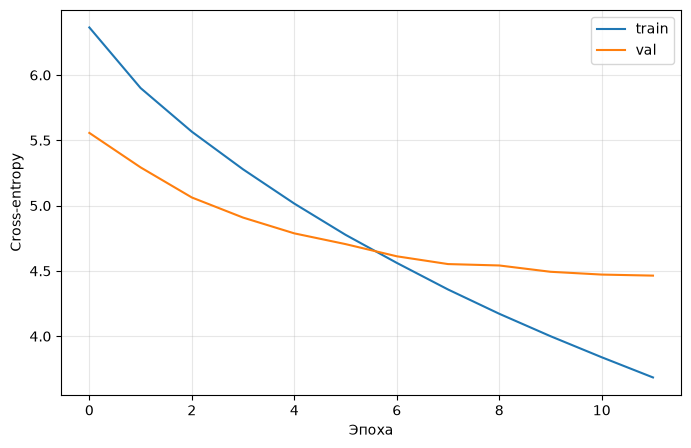


Запрос: 'князь андрей'
  <unk>           0.2695
  его             0.0152
  на              0.0135
  впервые         0.0123
  русской         0.0102

Запрос: 'мама мыла'
  <unk>           0.2996
  править         0.0759
  в               0.0556
  и               0.0329
  п               0.0168

Запрос: 'он сказал что'
  я               0.3533
  и               0.1300
  <unk>           0.0996
  в               0.0371
  из              0.0248

Жадная генерация: князь андрей <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>


In [12]:
# TODO(student): реализуйте оценку, график, top-k прогноз и генерацию.
final_val_loss = evaluate_loss(model, val_loader)
perplexity = math.exp(final_val_loss)
print(f"val_loss = {final_val_loss:.4f}")
print(f"perplexity = {perplexity:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(history["loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("Эпоха")
plt.ylabel("Cross-entropy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


def predict_top_k(model, prompt: str, k: int = 5):
    model.eval()
    tokens = normalize_text(prompt)
    ids = [BOS_IDX] + [stoi.get(w, UNK_IDX) for w in tokens]
    ids = ids[-MAX_SEQUENCE_LENGTH:]
    input_ids = torch.tensor([ids], dtype=torch.long, device=DEVICE)
    with torch.no_grad():
        logits = model(input_ids)
    probs = F.softmax(logits[0, -1, :], dim=-1)
    top_probs, top_ids = torch.topk(probs, k)
    return [(itos[i.item()], float(p)) for i, p in zip(top_ids, top_probs)]


def generate_greedy(model, prompt: str, max_new_tokens: int = 20):
    model.eval()
    tokens = normalize_text(prompt)
    ids = [BOS_IDX] + [stoi.get(w, UNK_IDX) for w in tokens]
    for _ in range(max_new_tokens):
        context = ids[-MAX_SEQUENCE_LENGTH:]
        input_ids = torch.tensor([context], dtype=torch.long, device=DEVICE)
        with torch.no_grad():
            logits = model(input_ids)
        next_id = int(logits[0, -1, :].argmax().item())
        if next_id == EOS_IDX:
            break
        ids.append(next_id)
    return " ".join(itos.get(i, "<unk>") for i in ids[1:])


for prompt in ["князь андрей", "мама мыла", "он сказал что"]:
    print(f"\nЗапрос: {prompt!r}")
    for word, prob in predict_top_k(model, prompt, k=5):
        print(f"  {word:<15} {prob:.4f}")

print("\nЖадная генерация:", generate_greedy(model, "князь андрей", 20))

## Этап 8. Самопроверка перед сдачей

- Использован RuHeritage-Corpus, его поле «text», каталог данных
  «data» и закреплённая ревизия.
- Словарь построен только по обучающей части; индексы PAD, UNK, BOS,
  EOS равны 0, 1, 2, 3.
- «input_ids» и «target_ids» имеют форму $(B,T)$, $T\leq32$.
- Эмбеддинги и скрытые состояния имеют форму $(B,T,128)$; логиты —
  $(B,T,V)$.
- PAD исключён из кросс-энтропии, а не заменён на обычную цель.
- Потери и перплексия конечны; сохранена лучшая валидационная модель.
- В коде нет TensorFlow, Keras и готового «nn.RNN».